Name: Christian Aron Vea

GitHub: https://github.com/ChristianAronVea/IND320-Vea

Streamlit: https://ind320-vea-5sc8vxsjg7v4bjgnpamvfl.streamlit.app/

Recording: 


AI usage and log can be found in separate files in the repo.

In [ ]:
import requests
import pandas as pd
from river import time_series, linear_model, preprocessing, optim, metrics
import calendar, math, itertools
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

### Checking Norweigan bank API

In [221]:
# API for euro and usd from nowegian bank
url_bank = ("https://data.norges-bank.no/api/data/EXR/B.USD+EUR.NOK.SP?endPeriod=2026-11-26&format=sdmx-json&locale=no&startPeriod=2025-11-26")

r = requests.get(url_bank, timeout=10)
print(r.status_code)        # 200 is ok

data_bank = r.json()
print(data_bank.keys())

df_bank = pd.DataFrame(data_bank)
df_bank

200
dict_keys(['meta', 'data'])


,meta,data
id,IREF146715,NaN
prepared,2026-11-26T17:37:58,NaN
test,False,NaN
datasetId,ffc6c642-d077-4aa4-9eb4-c2580c02c707,NaN
sender,{'id': 'Unknown'},NaN
receiver,{'id': 'guest'},NaN
links,"[{'rel': 'self', 'href': '/data/EXR/B.USD+EUR....",NaN
dataSets,NaN,"[{'links': [{'rel': 'dataflow', 'urn': 'urn:sd..."
structure,NaN,"{'links': [{'rel': 'dataflow', 'urn': 'urn:sdm..."


In [222]:
# Getting the currency rates fron NB
def get_nb_rates(start, end, currencies=("USD", "EUR")):
    """    Start and end has format:  yyyy-mm-dd """
    
    url = (f"https://data.norges-bank.no/api/data/EXR/B.{'+'.join(currencies)}.NOK.SP"
           f"?startPeriod={start}&endPeriod={end}&format=sdmx-json")
    j = requests.get(url, timeout=30).json()["data"]
    dates = [v["id"] for v in j["structure"]["dimensions"]["observation"][0]["values"]]
    base_dim = [d for d in j["structure"]["dimensions"]["series"] if d["id"] == "BASE_CUR"][0]
    rows = []
    for key, s in j["dataSets"][0]["series"].items():
        cur = base_dim["values"][int(key.split(":")[1])]["id"]
        for i, obs in s["observations"].items():
            rows.append((dates[int(i)], cur, float(obs[0])))
    df = pd.DataFrame(rows, columns=["date", "currency", "rate"])
    df["date"] = pd.to_datetime(df["date"])
    return df

In [223]:
# Testing function to retrive NB data
bank_data = get_nb_rates("2026-02-01", "2026-02-04")
bank_data

,date,currency,rate
0,2026-02-02,USD,9.6837
1,2026-02-03,USD,9.6788
2,2026-02-04,USD,9.6442
3,2026-02-02,EUR,11.4655
4,2026-02-03,EUR,11.4220
5,2026-02-04,EUR,11.3995


In [224]:
# Timezones
"""
From searching through previous assignments, I can find that all APIs use the same time zones - local or Europe/Oslo.
"""

'\nFrom searching through previous assignments, I can find that all APIs use the same time zones - local or Europe/Oslo.\n'

### Making River Framework on SARIMAX

In [263]:
magasinstatistikk = requests.get("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData")

df_mag = pd.DataFrame(magasinstatistikk.json())
df_mag = df_mag.sort_values(by="dato_Id")
df_mag = df_mag[df_mag["omrnr"] == 4]       # choosing region 4
df_mag

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
8285,1995-01-08,EL,4,1995,1,0.542160,21.079208,11.428300,0001-01-01T00:00:00,0.686501,-0.144341
8272,1995-01-15,EL,4,1995,2,0.525037,21.079208,11.067362,0001-01-01T00:00:00,0.542160,-0.017123
8232,1995-01-22,EL,4,1995,3,0.506964,21.079208,10.686392,0001-01-01T00:00:00,0.525037,-0.018073
8162,1995-01-29,EL,4,1995,4,0.486522,21.079208,10.255507,0001-01-01T00:00:00,0.506964,-0.020441
8255,1995-02-05,EL,4,1995,5,0.466650,21.079208,9.836613,0001-01-01T00:00:00,0.486522,-0.019872
...,...,...,...,...,...,...,...,...,...,...,...
8126,2026-10-25,EL,4,2026,43,0.904819,21.079208,19.072859,2026-11-04T13:00:00,0.903060,0.001759
8132,2026-11-01,EL,4,2026,44,0.905202,21.079208,19.080936,2026-11-11T13:00:00,0.904775,0.000427
8303,2026-11-08,EL,4,2026,45,0.920749,21.079208,19.408653,2026-11-18T13:00:00,0.905179,0.015570
8309,2026-11-15,EL,4,2026,46,0.919095,21.079208,19.373804,2026-11-25T13:00:00,0.920709,-0.001614


### Functions

In [264]:
from river import time_series

def pred_coming_months_fillings(X, horizon=12, history=520, p=1, d=0, q=0, m=52, sp=1, sd=0, sq=0):
    """Forecast and return a final-horizon holdout for one weekly series."""
    X = X.dropna().sort_index()

    train = X.iloc[-(horizon + history):-horizon]
    test = X.iloc[-horizon:]

    model = time_series.SNARIMAX(p, d, q, m, sp, sd, sq)
    for value in train:
        model.learn_one(float(value))

    forecast = model.forecast(horizon=horizon)

    return pd.DataFrame(
        {
            "date": df_mag["dato_Id"][-horizon:],
            "forecast": forecast,
            "real": test.to_numpy(dtype=float),
        }, 
    )

In [ ]:

def plotting_SARIMAX(results):

    plt.figure(figsize=(6, 5))

    plt.plot(results["date"], results["forecast"], label="Forecast")
    plt.plot(results["date"], results["real"], label="Actual")

    plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))

    plt.xlabel("Date")
    plt.ylabel("Values")
    plt.xticks(rotation=45)
    plt.title("Forecast vs Actual")
    plt.legend()

    plt.show()

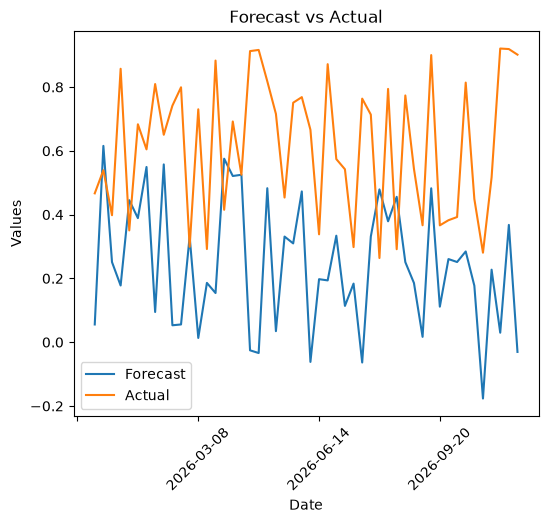

In [ ]:
# Testing the functions
X = df_mag['fyllingsgrad']         # The input. A pd.dataframe with the data sources

results = pred_coming_months_fillings(X, horizon=50, history=120, p=1, d=1, q=2, m=52, sp=1, sd=1, sq=1)

# Plot results
plotting_SARIMAX(results)

### Testing the model

In [280]:
def test_sarimax_settings(
    X,
    horizon = 26,
    histories = (52, 104, 260),
    orders = tuple(itertools.product(range(0, 4), repeat=3)),
    seasonal_orders = tuple(itertools.product(range(0, 4), repeat=3)),
    m_values = ((26, 52, 104))
):
    """Compare a small SARIMAX grid on the same final holdout period."""
    X = X.dropna().sort_index()
    if len(X) < max(histories) + horizon:
        raise ValueError(
            f"Need at least {max(histories) + horizon} weekly observations; "
            f"got {len(X)}."
        )

    rows = []
    for history, (p, d, q), (sp, sd, sq), m in itertools.product(
        histories, orders, seasonal_orders, m_values
    ):
        prediction = pred_coming_months_fillings(
            X, horizon, history, p, d, q, m, sp, sd, sq
        )
        error = prediction["real"] - prediction["forecast"]
        total_variation = ((prediction["real"] - prediction["real"].mean()) ** 2).sum()
        r2 = (
            1 - (error ** 2).sum() / total_variation
            if total_variation > 0 else float("nan")
        )
        rows.append(
            {
                "history_weeks": history,
                "p": p,
                "d": d,
                "q": q,
                "m": m,
                "sp": sp,
                "sd": sd,
                "sq": sq,
                "MAE": error.abs().mean(),
                "R2": r2,
            }
        )

    return pd.DataFrame(rows).sort_values(
        ["MAE", "R2"], ascending=[True, False]
    ).reset_index(drop=True)

In [ ]:
test_results = test_sarimax_settings(X, horizon=12)
display(test_results.round(4))

# Use the best row for the Streamlit defaults.
best_settings = test_results.iloc[0].to_dict()
best_settings

,history_weeks,p,d,q,m,sp,sd,sq,MAE,R2
0,260,4,3,3,52,3,1,0,8.720000e-02,7.604000e-01
1,260,4,3,3,52,4,1,0,8.720000e-02,7.604000e-01
2,260,4,3,3,52,5,1,0,8.720000e-02,7.604000e-01
3,520,2,2,1,52,5,1,2,1.126000e-01,6.332000e-01
4,520,5,2,5,52,1,1,0,1.220000e-01,6.431000e-01
...,...,...,...,...,...,...,...,...,...,...
559867,520,4,5,4,104,2,0,0,1.293845e+118,-3.160311e+238
559868,520,1,5,4,52,4,0,5,6.088529e+120,-6.998255e+243
559869,520,5,4,5,52,2,1,5,4.756750e+121,-4.271552e+245
559870,520,1,5,4,26,4,0,2,2.398044e+127,-1.085624e+257


{'history_weeks': 260.0,
 'p': 4.0,
 'd': 3.0,
 'q': 3.0,
 'm': 52.0,
 'sp': 3.0,
 'sd': 1.0,
 'sq': 0.0,
 'MAE': 0.08723187992682147,
 'R2': 0.7603783190523187}

In [ ]:
test_results26 = test_sarimax_settings(X, horizon=26)
display(test_results26.round(4))

,history_weeks,p,d,q,m,sp,sd,sq,MAE,R2
0,260,0,2,1,104,0,1,1,0.1552,1.772000e-01
1,260,0,2,1,104,0,1,2,0.1552,1.772000e-01
2,260,0,2,1,104,0,1,3,0.1552,1.772000e-01
3,260,3,3,3,52,2,1,0,0.1674,1.309000e-01
4,260,0,0,0,52,2,1,0,0.1719,1.089000e-01
...,...,...,...,...,...,...,...,...,...,...
36859,260,0,3,3,26,2,3,2,943.3496,-3.498258e+07
36860,260,0,3,3,26,1,3,3,982.1843,-3.751497e+07
36861,260,0,3,3,26,1,3,2,1011.3841,-3.917150e+07
36862,260,0,3,3,26,0,3,3,1049.6534,-3.509148e+07


{'history_weeks': 260.0,
 'p': 0.0,
 'd': 3.0,
 'q': 3.0,
 'm': 26.0,
 'sp': 0.0,
 'sd': 3.0,
 'sq': 1.0,
 'MAE': 1262.291182666765,
 'R2': -59368233.89630938}

In [283]:
best_settings_2 = test_results26.iloc[1].to_dict()
best_settings_2

{'history_weeks': 260.0,
 'p': 0.0,
 'd': 2.0,
 'q': 1.0,
 'm': 104.0,
 'sp': 0.0,
 'sd': 1.0,
 'sq': 2.0,
 'MAE': 0.1551559184780243,
 'R2': 0.17716088353652026}

In [288]:
test_results52 = test_sarimax_settings(X, horizon=52)
display(test_results52.round(4))

best_settings_3 = test_results52.iloc[1].to_dict()
best_settings_3

,history_weeks,p,d,q,m,sp,sd,sq,MAE,R2
0,260,3,1,0,26,2,1,2,0.1757,9.700000e-03
1,260,3,0,3,26,3,1,1,0.1758,3.880000e-02
2,260,2,1,0,26,3,1,1,0.1765,-9.390000e-02
3,260,3,0,2,26,3,1,1,0.1775,2.450000e-02
4,260,2,1,0,26,2,1,2,0.1777,-4.400000e-02
...,...,...,...,...,...,...,...,...,...,...
36859,260,0,3,2,26,0,2,1,3260.5073,-4.930363e+08
36860,260,0,3,3,26,0,2,2,3488.5509,-5.590322e+08
36861,260,3,3,3,26,0,3,0,3559.5309,-6.828280e+08
36862,260,0,3,2,26,1,3,0,3605.2001,-6.790292e+08


{'history_weeks': 260.0,
 'p': 3.0,
 'd': 0.0,
 'q': 3.0,
 'm': 26.0,
 'sp': 3.0,
 'sd': 1.0,
 'sq': 1.0,
 'MAE': 0.17582953114770428,
 'R2': 0.03875926851379663}

#### Ploting best model

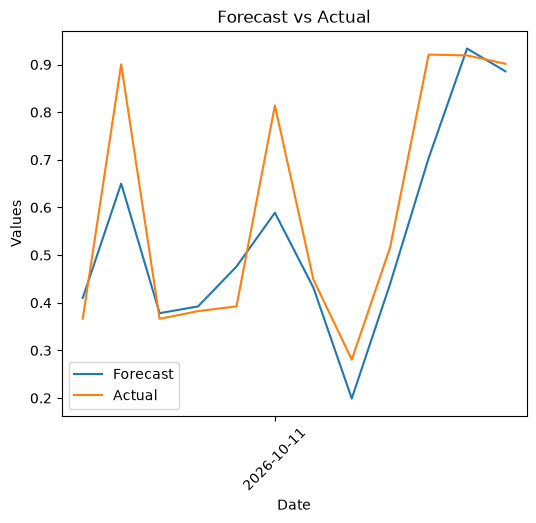

In [274]:
X = df_mag['fyllingsgrad']         # The input. A pd.dataframe with the data sources

best_results = pred_coming_months_fillings(
    X,
    horizon=12,
    history=int(best_settings["history_weeks"]),
    p=int(best_settings["p"]),
    d=int(best_settings["d"]),
    q=int(best_settings["q"]),
    m=int(best_settings["m"]),
    sp=int(best_settings["sp"]),
    sd=int(best_settings["sd"]),
    sq=int(best_settings["sq"]),
)

# Plot results
plotting_SARIMAX(best_results)

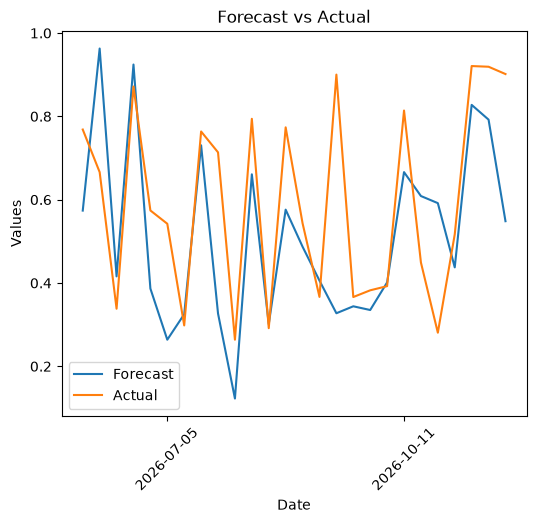

In [ ]:
# Horizon 26
X = df_mag['fyllingsgrad']         # The input. A pd.dataframe with the data sources

best_results = pred_coming_months_fillings(
    X,
    horizon=26,
    history=int(best_settings_2["history_weeks"]),
    p=int(best_settings_2["p"]),
    d=int(best_settings_2["d"]),
    q=int(best_settings_2["q"]),
    m=int(best_settings_2["m"]),
    sp=int(best_settings_2["sp"]),
    sd=int(best_settings_2["sd"]),
    sq=int(best_settings_2["sq"]),
)

# Plot results
plotting_SARIMAX(best_results)

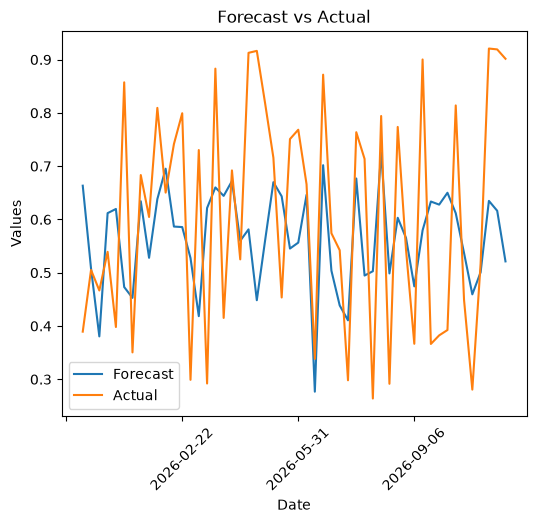

In [298]:
# Horizon 52
X = df_mag['fyllingsgrad']         # The input. A pd.dataframe with the data sources

best_results = pred_coming_months_fillings(
    X,
    horizon=52,
    history=int(best_settings_3["history_weeks"]),
    p=int(best_settings_3["p"]),
    d=int(best_settings_3["d"]),
    q=int(best_settings_3["q"]),
    m=int(best_settings_3["m"]),
    sp=int(best_settings_3["sp"]),
    sd=int(best_settings_3["sd"]),
    sq=int(best_settings_3["sq"]),
)

# Plot results
plotting_SARIMAX(best_results)

### Explaining testing

In [ ]:
"""
In the search of the best parameters, I made a function to test: test_sarimax_settings().
It runs over a selection of different selections for each parameter:
    histories = (52, 104, 260),
    orders = tuple(itertools.product(range(0, 4), repeat=3)),
    seasonal_orders = tuple(itertools.product(range(0, 4), repeat=3)),
    m_values = ((26, 52, 104))

When running, you deside horizon and input (X). Here the input is the weekly filling from Magasinstatistikk. 
There are the plots, one from each test. I tested horizon = 12, 26 and 52. During the first run, on 12 horizon, I saw
that the model preformed well until the horizon and very poorly after. Therefore I wanted to test on longer horizons. 

The plots clearly show that prediction becomes harder when having longer horizons. Its good at 12, ok at 26 and at 52 it 
doesnt work to well. 
"""

### Sketch for changes in navigation

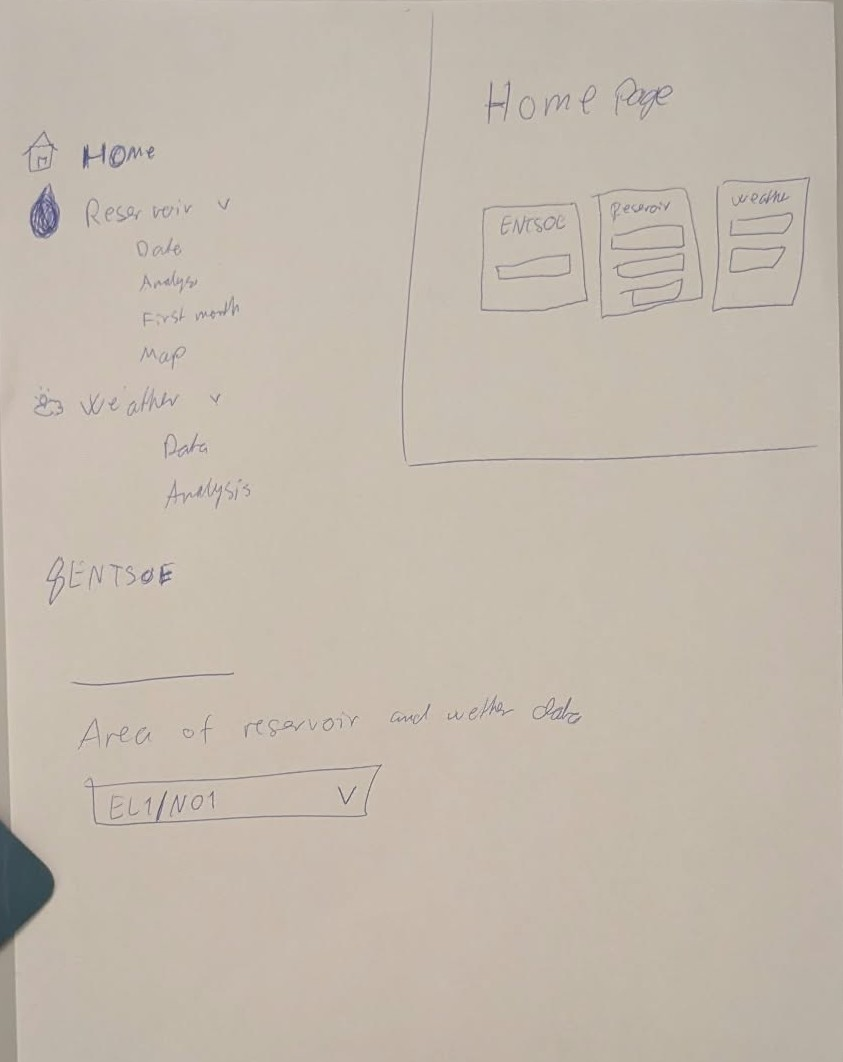

In [4]:
from IPython.display import display, Image

display(Image(filename="data/sketch.jpg"))